# 01 · Raw data acquisition and preprocessing

**Purpose:** download the source data when needed, then create the inputs for **[02 · Imagery coverage and crash matching](02_imagery_crash_matching.ipynb)**.

**Run:** choose the project `.venv` Python kernel, then **Restart Kernel and Run All Cells**.

**First run without data:** Save `MAPILLARY_ACCESS_TOKEN=your_token_here` in a `.env` file in the project root. The notebook reads this file when downloading Mapillary data. Requires `python-dotenv` (`pip install python-dotenv`).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
from shapely.geometry import box
import shapely

ROOT = Path.cwd()
if not (ROOT / "01_raw_data_preprocessing.ipynb").exists():
    raise RuntimeError("Open this notebook from the project root containing both notebooks.")
RAW = ROOT / "data" / "raw"
CACHE = ROOT / "data" / "processed"
RAW.mkdir(parents=True, exist_ok=True)
FIGURES = ROOT / "figures"
CACHE.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
TEAL, ORANGE, GRAY = "#167d8d", "#d66b36", "#c6cdd1"

def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


In [ ]:
CRS = "EPSG:26986"  # Coordinate system for Massachusetts; distances are measured in meters.
YEARS = [2023, 2024, 2025]  # Crash years included in the analysis.
CUTOFF = pd.Timestamp("2023-01-01T00:00:00Z")  # Keep images captured before this date (UTC).
SEARCH_M = 50.0  # Padding around the download area, in meters.


## 1. Download or reuse the raw source data

The code below uses the source URLs stored in this notebook. It asks ArcGIS for matching row IDs, downloads those rows in batches, and checks that every requested ID was returned. A **manifest** records the query and completed batches, so rerunning resumes an interrupted download. Existing complete batches are verified and reused.

First download the municipal boundaries; then select Boston and towns sharing more than 1 m of boundary. After selection, download roads and crashes for that area. A **bounding box** is a rectangle around the selected towns, padded by 50 m.

API reference: [ArcGIS layer queries](https://developers.arcgis.com/rest/services-reference/enterprise/query-feature-service-layer/).

In [3]:
import hashlib
import math
import os
import time
from datetime import datetime, timezone
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from pyproj import Transformer

def now():
    return datetime.now(timezone.utc).isoformat()

def read_json(path):
    return json.loads(Path(path).read_text())

def write_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(obj, indent=2, allow_nan=False, default=str) + "\n")
    temp.replace(path)

def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()

SOURCE_SETTINGS = {
    # Map coordinate system; distances are in meters (also defined as CRS above).
    "crs": 'EPSG:26986',
    # Download images captured before this UTC date.
    "image_cutoff": '2023-01-01T00:00:00Z',
    # Crash years; also defined as YEARS above.
    "outcome_years": [2023, 2024, 2025],
    # Study center; the town-selection code below explicitly uses Boston.
    "anchor_municipality": 'BOSTON',
    # Shared border must exceed 1 meter; the selection code below also uses 1.
    "boundary_min_shared_m": 1.0,
    # Extra image-search area around the study and roads, in meters.
    "candidate_radius_m": 50.0,
    # Reserved random seed for a future data split; unused in these notebooks.
    "split_seed": 506,
    # Reserved test-data share (20%); unused in these notebooks.
    "test_fraction": 0.2,
    # Side length of each initial Mapillary query square, in meters.
    "image_tile_size_m": 2000,
    # Stop splitting squares at this size; split capture-time intervals instead.
    "image_min_tile_size_m": 125,
    # Maximum images requested per query; split queries that reach this limit.
    "image_response_limit": 2000,
    # Planned manual-review count per source; unused in these notebooks.
    "review_per_source": 50,

    # ArcGIS dataset URLs used by api.download().
    "sources": {
        # Massachusetts city and town shapes, used to select the study area.
        "boundaries": "https://services8.arcgis.com/o4UVke7qqC8oNJ7j/ArcGIS/rest/services/Massachusetts_Towns_General_Coast/FeatureServer/0",
        # 2022 MassDOT road inventory: road shapes and attributes.
        "roads": "https://gis.massdot.state.ma.us/arcgis/rest/services/Roads/RoadInventoryYearEndFiles/FeatureServer/8",
        # 2023 MassDOT crash records.
        "crashes_2023": "https://gis.crashdata.dot.mass.gov/arcgis/rest/services/MassDOT/MASSDOT_ODP_OPEN_2023v/FeatureServer/0",
        # 2024 MassDOT crash records.
        "crashes_2024": "https://gis.crashdata.dot.mass.gov/arcgis/rest/services/MassDOT/MASSDOT_ODP_OPEN_2024/FeatureServer/0",
        # 2025 MassDOT crash records.
        "crashes_2025": "https://gis.crashdata.dot.mass.gov/arcgis/rest/services/MassDOT/MASSDOT_ODP_OPEN_2025/FeatureServer/0",
    },
}

def config():
    return SOURCE_SETTINGS.copy()

class SourceError(RuntimeError):
    pass

class ArcGIS:
    def __init__(self):
        self.session = requests.Session()
        retry = Retry(total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
                      allowed_methods=['GET', 'POST'])
        self.session.mount('https://', HTTPAdapter(max_retries=retry))

    def get(self, url, params):
        # ArcGIS read-only queries support POST; avoid long-URL server limits.
        response = (self.session.post(url, data=params, timeout=(15, 120)) if url.endswith('/query')
                    else self.session.get(url, params=params, timeout=(15, 120)))
        response.raise_for_status()
        payload = response.json()
        if 'error' in payload:
            error = payload['error']
            raise SourceError(f"ArcGIS {error.get('code')}: {error.get('message')}")
        return payload

    def download(self, name, url, where='1=1', spatial=None):
        folder = RAW / name
        folder.mkdir(parents=True, exist_ok=True)
        schema_path = folder / 'schema.json'
        schema = read_json(schema_path) if schema_path.exists() else self.get(url, {'f': 'json'})
        write_json(schema_path, schema)
        oid = schema.get('objectIdField') or next(f['name'] for f in schema['fields'] if f['type'] == 'esriFieldTypeOID')
        query = {'f': 'json', 'where': where, **(spatial or {})}
        signature = digest({'url': url, 'query': query})
        manifest_path = folder / 'manifest.json'
        if manifest_path.exists():
            manifest = read_json(manifest_path)
            if manifest['query_hash'] != signature:
                raise SourceError(f'Query changed for {name}; archive its cache before changing the frame.')
            ids = manifest['requested_ids']
        else:
            response = self.get(url + '/query', {**query, 'returnIdsOnly': 'true'})
            if 'objectIds' not in response:
                raise SourceError(f'{name}: source did not return an object-ID list')
            ids = sorted(response['objectIds'] or [])
            manifest = {'url': url, 'where': where, 'spatial_filter': spatial, 'query_hash': signature,
                        'object_id_field': oid, 'requested_ids': ids, 'retrieved_at': now(), 'status': 'partial'}
            write_json(manifest_path, manifest)
        features = []
        size = min(500, int(schema.get('maxRecordCount', 500)))
        try:
            for start in range(0, len(ids), size):
                batch_ids = ids[start:start + size]
                path = folder / f'batch_{start:08d}.geojson'
                if path.exists():
                    batch = read_json(path)
                else:
                    batch = self.get(url + '/query', {'f': 'geojson', 'objectIds': ','.join(map(str, batch_ids)),
                        'outFields': '*', 'returnGeometry': 'true', 'outSR': 26986})
                    got = [f['properties'][oid] for f in batch.get('features', [])]
                    if sorted(got) != batch_ids or len(got) != len(set(got)) or batch.get('exceededTransferLimit'):
                        raise SourceError(f'{name}: incomplete or duplicate source-ID batch at {start}')
                    write_json(path, batch)
                got = [f['properties'][oid] for f in batch.get('features', [])]
                if sorted(got) != batch_ids:
                    raise SourceError(f'{name}: cached source-ID batch does not reconcile')
                features.extend(batch['features'])
                if start % 5000 == 0:
                    print(f'{name}: {len(features):,}/{len(ids):,} verified records', flush=True)
            manifest.update(status='complete', downloaded_records=len(features), completed_at=now())
            write_json(manifest_path, manifest)
        except Exception as exc:
            manifest.update(status='failed', error_type=type(exc).__name__, failed_at=now())
            write_json(manifest_path, manifest)
            raise
        if not features:
            return gpd.GeoDataFrame(columns=[f['name'] for f in schema['fields']] + ['geometry'], geometry='geometry', crs=26986)
        return gpd.GeoDataFrame.from_features(features, crs=26986)

api = ArcGIS()
api.download("boundaries", SOURCE_SETTINGS["sources"]["boundaries"])

boundaries: 351/351 verified records


,geometry,FID,TOWN,TOWN_ID,TYPE,COUNTY,FIPS_STCO,FOURCOLOR,POP1960,POP1970,...,POP2010,POP2020,POPCH10_20,AREA_ACRES,AREA_SQMI,SHAPE_Leng,PCTCH10_20,Shape__Area,Shape__Length,Town_Lowercase
0,"POLYGON ((217255.492 836086.505, 215267.453 83...",1,SEEKONK,265,T,BRISTOL,25005,2,8399,11116,...,13722,15531,1809,11932.581,18.645,36129.414061,13.183209,4.828947e+07,36129.414061,Seekonk
1,"POLYGON ((242739.123 850918.935, 242754.672 85...",2,LAKEVILLE,146,T,PLYMOUTH,25023,4,3209,4376,...,10602,11523,921,23116.239,36.119,47022.080298,8.687040,9.354812e+07,47022.080298,Lakeville
2,"POLYGON ((224212.852 850986.925, 225395.392 85...",3,REHOBOTH,247,T,BRISTOL,25005,1,4953,6512,...,11608,12502,894,30380.210,47.470,48076.072216,7.701585,1.229558e+08,48076.072217,Rehoboth
3,"POLYGON ((261908.083 853925.295, 262148.083 85...",4,CARVER,52,T,PLYMOUTH,25023,4,1949,2420,...,11509,11645,136,25422.364,39.722,47726.190678,1.181684,1.028806e+08,47726.190678,Carver
4,"POLYGON ((249036.322 857499.955, 249043.002 85...",5,MIDDLEBOROUGH,182,T,PLYMOUTH,25023,3,11065,13607,...,23116,24245,1129,46208.985,72.201,72570.783384,4.884063,1.870011e+08,72570.783384,Middleborough
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
346,"POLYGON ((250194.972 959315.315, 253308.672 95...",347,SALISBURY,259,T,ESSEX,25009,4,3154,4179,...,8283,9236,953,10113.036,15.802,30751.225042,11.505493,4.208501e+07,30750.397354,Salisbury
347,"MULTIPOLYGON (((248384.107 797715.645, 248386....",348,GOSNOLD,109,T,DUKES,25007,3,66,83,...,75,70,-5,8603.996,13.441,90636.449199,-6.666667,3.437555e+07,90614.363179,Gosnold
348,"POLYGON ((236560.782 924900.225, 236574.733 92...",349,LYNNFIELD,164,T,ESSEX,25009,4,8398,10826,...,11596,13000,1404,6683.367,10.443,27878.230478,12.107623,2.704235e+07,27878.230478,Lynnfield
349,"POLYGON ((235427.602 919563.805, 235530.722 91...",350,WAKEFIELD,305,T,MIDDLESEX,25017,2,24295,25402,...,24932,27090,2158,5116.225,7.994,22390.042685,8.655543,2.070844e+07,22390.042685,Wakefield


| Input | One source row | Role |
|---|---|---|
| Municipal boundaries | Municipal polygon | Select the study area and locate points |
| 2022 road inventory | Original road line record | Road attributes and possible matches |
| 2023–2025 crashes | Source-layer crash record | Reported crash location and junction type |
| Mapillary metadata | Image metadata record | Capture date and position; not photo pixels |

In [4]:
def load_source(name):
    folder = RAW / name
    manifest = json.loads((folder / "manifest.json").read_text())
    if manifest["status"] != "complete":
        raise ValueError(f"Incomplete source download: {name}")
    features = []
    for path in sorted(folder.glob("batch_*.geojson")):
        features.extend(json.loads(path.read_text())["features"])
    oid = manifest["object_id_field"]
    observed = [feature["properties"][oid] for feature in features]
    assert len(observed) == len(set(observed)), f"Repeated source IDs within {name}"
    assert sorted(observed) == manifest["requested_ids"], f"Source-ID mismatch: {name}"
    if not features:
        schema = read_json(folder / "schema.json")
        return gpd.GeoDataFrame(columns=[f["name"] for f in schema["fields"]] + ["geometry"],
                                geometry="geometry", crs=CRS)
    return gpd.GeoDataFrame.from_features(features, crs=CRS)

towns = load_source("boundaries")
towns["municipality"] = towns.TOWN.str.strip().str.upper()
assert towns.municipality.is_unique
boston = towns.loc[towns.municipality.eq("BOSTON")].geometry.union_all()
towns["shared_boundary_m"] = towns.geometry.boundary.intersection(boston.boundary).length
frame = towns.loc[towns.municipality.eq("BOSTON") | towns.shared_boundary_m.gt(1)].copy()
frame = frame.sort_values("municipality").reset_index(drop=True)
frame.to_parquet(CACHE / "study_municipalities.parquet")
display(Markdown(f"**Study area: {len(frame)} municipalities.** " + ", ".join(frame.municipality.str.title()) + "."))

**Study area: 13 municipalities.** Boston, Brookline, Cambridge, Dedham, Everett, Milton, Needham, Newton, Quincy, Revere, Somerville, Watertown, Winthrop.

In [5]:
town_ids = ",".join(map(str, sorted(frame.TOWN_ID.astype(int))))
minx, miny, maxx, maxy = frame.total_bounds
envelope = {"geometry": f"{minx-SEARCH_M},{miny-SEARCH_M},{maxx+SEARCH_M},{maxy+SEARCH_M}",
            "geometryType": "esriGeometryEnvelope", "inSR": 26986,
            "spatialRel": "esriSpatialRelIntersects"}
api.download("roads", SOURCE_SETTINGS["sources"]["roads"], f"City IN ({town_ids})")
api.download("roads_context", SOURCE_SETTINGS["sources"]["roads"], f"City NOT IN ({town_ids})", envelope)
quoted = ",".join("'" + name.replace("'", "''") + "'" for name in frame.municipality)
for year in YEARS:
    name = f"crashes_{year}"
    api.download(name, SOURCE_SETTINGS["sources"][name], f"CITY_TOWN_NAME IN ({quoted})")
    api.download(name + "_spatial", SOURCE_SETTINGS["sources"][name], "1=1", envelope)
print("Road and crash downloads verified; ready for preprocessing.")

roads: 500/55,143 verified records


roads: 5,500/55,143 verified records


roads: 10,500/55,143 verified records


roads: 15,500/55,143 verified records


roads: 20,500/55,143 verified records


roads: 25,500/55,143 verified records


... (36 outputs left out)

crashes_2025_spatial: 10,500/22,814 verified records


crashes_2025_spatial: 15,500/22,814 verified records


crashes_2025_spatial: 20,500/22,814 verified records


Road and crash downloads verified; ready for preprocessing.


## 2. Standardize roads and record quality issues

We preserve original source columns and add readable fields. Each `segment_id` identifies one original inventory line; we do not split or merge roads.

- **Geometry and facility:** flag missing/invalid lines, zero length, and bicycle/pedestrian-only facilities. These remain in the inventory but cannot be candidate roads.
- **Units:** compute geometry length in meters and convert the source `Length` from miles to meters.
- **Numeric attributes:** nonpositive or unparseable AADT, speed, and lane values become missing in cleaned fields. We do not impute them.
- **AADT year:** retain only years 1900–2022. A missing year means unknown timing, not an assumed 2022 measurement.
- **Municipality:** retain the reported municipality and compare it with the road midpoint's spatial municipality. Boundary ties remain visible.

**Outside-study roads** downloaded within the padded bounding box remain possible matches. They are excluded from study-road denominators.

In [6]:
def geometry_status(frame, allowed):
    return pd.Series(np.select(
        [frame.geometry.isna(), frame.geometry.is_empty,
         ~frame.geom_type.isin(allowed), ~frame.geometry.is_valid],
        ["missing_geometry", "empty_geometry", "unexpected_geometry_type", "invalid_geometry"],
        default="valid"), index=frame.index)

def spatial_municipality(frame):
    valid = frame.loc[frame.geometry.notna() & frame.geometry.is_valid & ~frame.geometry.is_empty]
    result = pd.Series(pd.NA, index=frame.index, dtype="string")
    if len(valid):
        hits = gpd.sjoin(valid[["geometry"]], towns[["municipality", "geometry"]],
                         how="left", predicate="intersects")
        names = hits.groupby(level=0).municipality.agg(lambda s: "|".join(sorted(set(s.dropna()))))
        result.loc[names.index] = names.replace("", pd.NA)
    return result

schema = json.loads((RAW / "roads" / "schema.json").read_text())
domains = {field["name"]: {v["code"]: v["name"] for v in
           (field.get("domain") or {}).get("codedValues", [])} for field in schema["fields"]}
city_names = towns.set_index("TOWN_ID").municipality.to_dict()

def standardize_roads(raw):
    r = raw.copy().reset_index(drop=True)
    r["segment_id"] = "2022:" + r.OBJECTID.astype("Int64").astype(str)
    assert r.segment_id.is_unique
    r["municipality"] = r.City.map(city_names).astype("string")
    r["road_name"] = r.St_Name.astype("string")
    r["road_class"] = r.F_Class.map(domains["F_Class"]).fillna("Unknown")
    r["facility_name"] = r.Facility.map(domains["Facility"]).fillna("Unknown")
    r["geometry_status"] = geometry_status(r, ["LineString", "MultiLineString"])
    r["length_m"] = r.geometry.length
    r["source_length_m"] = pd.to_numeric(r.Length, errors="coerce") * 1609.344
    r["road_status"] = np.select(
        [r.geometry_status.ne("valid"), r.length_m.le(0), r.Facility.eq(12)],
        ["invalid_geometry", "zero_length", "bicycle_pedestrian_facility"], default="eligible")
    r["eligible"] = r.road_status.eq("eligible")
    midpoint = r[["geometry"]].copy()
    midpoint.geometry = midpoint.geometry.where(r.geometry_status.eq("valid"))
    midpoint.geometry = midpoint.geometry.interpolate(0.5, normalized=True)
    r["spatial_municipality"] = spatial_municipality(midpoint)
    r["municipality_disagreement"] = r.spatial_municipality.notna() & r.spatial_municipality.ne(r.municipality)
    for original, clean in [("AADT", "aadt"), ("Speed_Lim", "speed"), ("Num_Lanes", "lanes")]:
        value = pd.to_numeric(r[original], errors="coerce")
        r[clean] = value.where(value.gt(0))
        r[clean + "_nonpositive_or_missing"] = value.isna() | value.le(0)
    year = pd.to_numeric(r.AADT_Year, errors="coerce")
    r["aadt_year"] = year.where(year.between(1900, 2022))
    r["aadt_has_known_preoutcome_year"] = r.aadt.notna() & r.aadt_year.notna()
    return r

roads = standardize_roads(load_source("roads"))
context = standardize_roads(load_source("roads_context"))
candidates = gpd.GeoDataFrame(pd.concat([roads.loc[roads.eligible], context.loc[context.eligible]],
                                      ignore_index=True), crs=CRS)
assert candidates.segment_id.is_unique
roads.to_parquet(CACHE / "roads.parquet")
candidates.to_parquet(CACHE / "road_candidates.parquet")
display(roads.road_status.value_counts().rename_axis("Road check result").to_frame("Records"))

,Records
Road check result,
eligible,54647
bicycle_pedestrian_facility,426
invalid_geometry,70


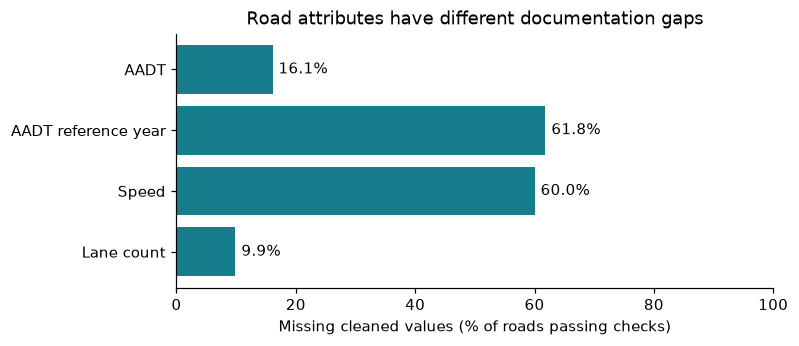

**24,999 roads have usable AADT but no usable reference year.** Keep these values flagged; their age is unknown. AADT is not required for spatial matching.

In [7]:
# A compact view of missing cleaned attributes; no rows are dropped here.
missing = roads.loc[roads.eligible, ["aadt", "aadt_year", "speed", "lanes"]].isna().mean() * 100
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(["AADT", "AADT reference year", "Speed", "Lane count"], missing, color=TEAL)
ax.set(xlabel="Missing cleaned values (% of roads passing checks)", xlim=(0, 100),
       title="Road attributes have different documentation gaps")
ax.invert_yaxis()
for i, value in enumerate(missing): ax.text(value + 1, i, f"{value:.1f}%", va="center")
save_figure(fig, "01_road_attribute_missingness")
unknown_year = roads.aadt.notna() & roads.aadt_year.isna()
display(Markdown(f"**{unknown_year.sum():,} roads have usable AADT but no usable reference year.** "
                 "Keep these values flagged; their age is unknown. AADT is not required for spatial matching."))

## 3. Combine the two crash downloads

The **reported-town query** captures crashes reporting a study municipality, even without coordinates. The **spatial query** captures points inside a rectangular bounding box padded by 50 m, even when the reported town is wrong or missing.

A row downloaded through both routes has the same `OBJECTID` within its yearly layer, so we keep one copy. `record_id = source_year:OBJECTID` identifies that source row. **`CRASH_NUMB` identifies the event**: if different retained rows share that ID, all are flagged for review rather than choosing one arbitrarily. Missing event IDs get separate placeholders and remain ineligible.

In [8]:
crash_parts, retrieval = [], []
for year in YEARS:
    reported = load_source(f"crashes_{year}")
    spatial = load_source(f"crashes_{year}_spatial")
    combined = pd.concat([reported.assign(acquisition_route="reported_town"),
                          spatial.assign(acquisition_route="spatial_envelope")], ignore_index=True)
    before = len(combined)
    combined = combined.drop_duplicates("OBJECTID", keep="first").copy()
    combined["source_year"] = year
    retrieval.append({"Year": year, "Reported town": len(reported), "Spatial query": len(spatial),
                      "Repeated copies removed": before-len(combined), "Retained": len(combined)})
    crash_parts.append(combined)
crashes = gpd.GeoDataFrame(pd.concat(crash_parts, ignore_index=True), crs=CRS)
crashes["record_id"] = crashes.source_year.astype(str) + ":" + crashes.OBJECTID.astype(str)
assert crashes.record_id.is_unique
crashes["crash_id_missing"] = crashes.CRASH_NUMB.isna()
crashes["crash_id"] = crashes.CRASH_NUMB.astype("Int64").astype("string")
crashes.loc[crashes.crash_id_missing, "crash_id"] = "missing:" + crashes.loc[crashes.crash_id_missing, "record_id"]
crashes["duplicate_crash_id"] = crashes.crash_id.duplicated(keep=False)
display(pd.DataFrame(retrieval).set_index("Year"))
display(Markdown(f"**{crashes.duplicate_crash_id.sum():,} records have duplicated event IDs after source-row deduplication.**"))
del crash_parts, reported, spatial, combined

,Reported town,Spatial query,Repeated copies removed,Retained
Year,,,,
2023,15840,24174,15014,25000
2024,15599,23492,14422,24669
2025,15152,22814,14428,23538


**0 records have duplicated event IDs after source-row deduplication.**

## 4. Assign crash quality flags and matching status

**`in_frame` means reported OR spatial municipality belongs to the study.** It is an inclusion flag for quality summaries, not a guarantee of usable location. Extra outside-study crashes stay in the cache.

`crash_status` records the **first condition that applies**, in this order:

| Status | Meaning |
|---|---|
| `outside_audit_frame` | Neither reported nor spatial municipality belongs to the study |
| `missing_crash_id` | Source event identifier is missing |
| `duplicate_crash_id_review` | Event identifier repeats across retained source rows |
| `invalid_geometry` | Point geometry is missing, empty, invalid, or wrong type |
| `outside_study_geometry` | Point is more than 50 m from the study polygons |
| `year_conflict` | Reported year is unexpected or disagrees with its source layer |
| `intersection` | Junction type is an intersection or traffic circle |
| `unknown_junction` | Junction type is missing, unknown, or invalid |
| `other_junction_pending_review` | Another junction type, such as a driveway or ramp |
| `eligible_for_matching` | All preceding checks pass; reported type is “Not at junction” |

A **junction** is where roads or traffic paths connect. The current study deliberately focuses on non-intersection crashes. These rules flag and retain records; they do not repair geometry or prove source accuracy.

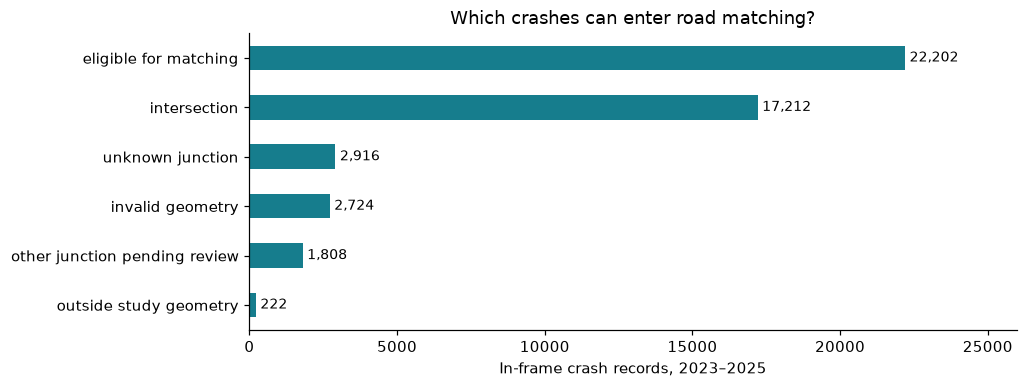

**47,084 in-frame records; 22,202 pass matching checks.** Zero-count statuses are absent from this chart. Source geocoding flags are retained; geometry is checked independently.

In [9]:
INTERSECTIONS = {"Four-way intersection", "T-intersection", "Y-intersection", "Five-point or more", "Traffic circle"}
UNKNOWN = {"Unknown", "Not reported", "Reported but invalid", ""}
def junction_category(value):
    value = "" if pd.isna(value) else str(value).strip()
    if value == "Not at junction": return "non_intersection"
    if value in INTERSECTIONS: return "intersection"
    if value in UNKNOWN: return "unknown"
    return "other_junction_pending_review"

crashes["reported_municipality"] = crashes.CITY_TOWN_NAME.astype("string").str.strip().str.upper()
crashes["spatial_municipality"] = spatial_municipality(crashes)
crashes["geometry_status"] = geometry_status(crashes, ["Point"])
crashes["municipality_disagreement"] = crashes.spatial_municipality.notna() & crashes.spatial_municipality.ne(crashes.reported_municipality)
crashes["in_reported_frame"] = crashes.reported_municipality.isin(frame.municipality)
study_names = set(frame.municipality)
spatial_in_frame = crashes.spatial_municipality.fillna("").str.split("|").map(lambda names: bool(set(names) & study_names))
crashes["in_frame"] = crashes.in_reported_frame | spatial_in_frame
crashes["junction_category"] = crashes.RDWY_JNCT_TYPE_DESCR.map(junction_category)
crashes["road_name"] = crashes.RDWY.astype("string")
crashes["event_time"] = pd.to_datetime(crashes.CRASH_DATETIME, unit="ms", errors="coerce", utc=True)
crashes["year"] = pd.to_numeric(crashes.YEAR, errors="coerce").astype("Int64")
crashes["year_disagreement"] = crashes.year.ne(crashes.source_year).fillna(True)
crashes["date_missing"] = crashes.event_time.isna()
crashes["distance_to_study_m"] = crashes.geometry.distance(frame.geometry.union_all())
conditions = [~crashes.in_frame, crashes.crash_id_missing, crashes.duplicate_crash_id,
              crashes.geometry_status.ne("valid"), crashes.distance_to_study_m.gt(50),
              ~crashes.year.isin(YEARS) | crashes.year_disagreement,
              crashes.junction_category.eq("intersection"), crashes.junction_category.eq("unknown"),
              crashes.junction_category.ne("non_intersection")]
statuses = ["outside_audit_frame", "missing_crash_id", "duplicate_crash_id_review", "invalid_geometry",
            "outside_study_geometry", "year_conflict", "intersection", "unknown_junction", "other_junction_pending_review"]
crashes["crash_status"] = np.select([c.fillna(False).to_numpy(dtype=bool) for c in conditions],
                                   statuses, default="eligible_for_matching")
crashes.to_parquet(CACHE / "crashes.parquet")
audit = crashes.loc[crashes.in_frame]
status_counts = audit.crash_status.value_counts()
fig, ax = plt.subplots(figsize=(9, 3.5))
status_counts.rename(index=lambda s: s.replace("_", " ")).sort_values().plot.barh(ax=ax, color=TEAL)
ax.set(xlabel="In-frame crash records, 2023–2025", ylabel="", title="Which crashes can enter road matching?")
for bar in ax.patches: ax.text(bar.get_width()+150, bar.get_y()+bar.get_height()/2, f"{int(bar.get_width()):,}", va="center", fontsize=9)
ax.set_xlim(0, status_counts.max()*1.17)
save_figure(fig, "01_crash_preparation")
display(Markdown(f"**{len(audit):,} in-frame records; {status_counts.get('eligible_for_matching', 0):,} pass matching checks.** "
                 "Zero-count statuses are absent from this chart. Source geocoding flags are retained; geometry is checked independently."))

### Download or reuse image metadata

Query Mapillary in 2 km tiles around the study and eligible roads, using captures before January 1, 2023. If an API response is capped, split its area or time interval rather than treating a truncated response as complete. The **collection ledger** stores query footprints, time intervals, and completion status; rerunning resumes unfinished queries.

A complete local cache needs no token or internet. A fresh collection requests a token only when queries remain. Access errors or rate limits stop collection with a saved checkpoint; rerun after resolving them. Only metadata is downloaded, not photographs.

API reference: [Mapillary image API](https://www.mapillary.com/developer/api-documentation#image).

In [10]:
import threading
_worker_state = threading.local()
LEDGER = RAW / "mapillary" / "ledger.json"

def initialize_tiles():
    cfg=config()
    frame=gpd.read_parquet(CACHE/'study_municipalities.parquet')
    roads=gpd.read_parquet(CACHE/'roads.parquet')
    roads=roads.loc[roads.eligible]
    # Recording completed human review does not invalidate image downloads.
    collection_cfg={k:v for k,v in cfg.items() if k not in {'matching_rules_reviewed','junction_policy_reviewed'}}
    signature=digest({'config':collection_cfg,'segments':sorted(roads.segment_id)})
    if LEDGER.exists():
        ledger=read_json(LEDGER)
        if ledger['configuration_hash']!=signature:
            raise ValueError('Image-audit configuration changed; archive the old ledger first.')
        for key, tile in ledger['tiles'].items():
            if 'children' not in tile and tile['status'] == 'complete':
                if not (RAW / 'mapillary' / 'batches' / f'{key}.json').exists():
                    tile['status'] = 'unqueried'
        _update_parent_status(ledger)
        return ledger
    # Test individual tiles against a spatial index rather than buffering a union
    # of tens of thousands of road lines (which is unnecessarily expensive).
    radius=cfg['candidate_radius_m']
    domain=frame.geometry.union_all().buffer(radius)
    bounds=np.array([domain.bounds, roads.total_bounds + np.array([-radius,-radius,radius,radius])])
    minx,miny=bounds[:,:2].min(axis=0);maxx,maxy=bounds[:,2:].max(axis=0)
    size=cfg['image_tile_size_m']
    tiles={}
    for x in range(math.floor(minx/size)*size,math.ceil(maxx/size)*size,size):
        for y in range(math.floor(miny/size)*size,math.ceil(maxy/size)*size,size):
            polygon=box(x,y,x+size,y+size)
            if polygon.intersects(domain) or len(roads.sindex.query(polygon,predicate='dwithin',distance=radius)):
                key=f'{x}_{y}'
                tiles[key]={'bounds_m':[x,y,x+size,y+size], 'status':'unqueried', 'start_ms':0,
                    'end_ms':int(pd.Timestamp(cfg['image_cutoff']).timestamp()*1000), 'depth':0}
    ledger={'configuration_hash':signature,'created_at':now(),'tiles':tiles,
            'capture_interval':'start inclusive, end exclusive; timestamps verified locally',
            'status':'unqueried','request_count':0}
    write_json(LEDGER,ledger)
    return ledger

def children_for_tile(tile,cfg):
    x0,y0,x1,y1=tile['bounds_m'];start,end=tile['start_ms'],tile['end_ms']
    depth=tile.get('depth',0)+1
    if max(x1-x0,y1-y0)>cfg['image_min_tile_size_m']:
        xm=(x0+x1)/2;ym=(y0+y1)/2
        bounds=[[x0,y0,xm,ym],[xm,y0,x1,ym],[x0,ym,xm,y1],[xm,ym,x1,y1]]
        return [dict(bounds_m=b,start_ms=start,end_ms=end,depth=depth,status='unqueried') for b in bounds]
    if end-start>1000:
        mid=(start+end)//2
        # A tiny overlap avoids endpoint loss; ID deduplication removes duplicates.
        return [dict(bounds_m=tile['bounds_m'],start_ms=a,end_ms=b,depth=depth,status='unqueried')
                for a,b in [(start,min(mid+1,end)),(mid,end)]]
    return []

def _update_parent_status(ledger):
    for key,tile in sorted(ledger['tiles'].items(),key=lambda kv:kv[1].get('depth',0),reverse=True):
        if 'children' in tile:
            tile['status']='complete' if all(ledger['tiles'][c]['status']=='complete' for c in tile['children']) else 'partial'
    roots=[t for t in ledger['tiles'].values() if t.get('depth',0)==0]
    ledger['status']='complete' if roots and all(t['status']=='complete' for t in roots) else 'partial'
    ledger['updated_at']=now()

def _request_tile(tile, cfg, token, retry_number=0):
    if retry_number:
        time.sleep(min(2 ** retry_number, 8))
    if not hasattr(_worker_state, 'session'):
        _worker_state.session = requests.Session()
        _worker_state.transform = Transformer.from_crs(26986, 4326, always_xy=True)
    session = _worker_state.session
    session.headers['Authorization'] = 'OAuth ' + token
    bounds = _worker_state.transform.transform_bounds(*tile['bounds_m'], densify_pts=21)
    params = {
        'bbox': ','.join(map(str, bounds)),
        'fields': 'id,geometry,captured_at,sequence,compass_angle',
        'start_captured_at': pd.Timestamp(tile['start_ms'], unit='ms', tz='UTC').isoformat(),
        'end_captured_at': pd.Timestamp(tile['end_ms'], unit='ms', tz='UTC').isoformat(),
        'limit': cfg['image_response_limit'],
    }
    try:
        response = session.get('https://graph.mapillary.com/images', params=params, timeout=(15, 60))
        try:
            payload = response.json()
        except ValueError:
            payload = {}
        error = payload.get('error', {})
        code = error.get('code')
        if 'reduce the amount of data' in str(error.get('message', '')).lower():
            return {'kind': 'split'}
        if response.status_code == 429 or code in {4, 17, 32, 613}:
            try:
                delay = min(max(float(response.headers.get('Retry-After', 60)), 1), 300)
            except ValueError:
                delay = 60
            return {'kind': 'rate_limited', 'http_status': response.status_code, 'retry_after_s': delay}
        if response.status_code in {401, 403} or code == 190:
            return {'kind': 'authentication', 'http_status': response.status_code}
        if response.status_code != 200 or error:
            return {'kind': 'failed', 'http_status': response.status_code,
                    'retryable': response.status_code in {408, 500, 502, 503, 504}}
        if not isinstance(payload.get('data'), list):
            return {'kind': 'failed', 'error_type': 'UnexpectedResponse', 'retryable': True}
        items = [{k: item.get(k) for k in ['id', 'geometry', 'captured_at', 'sequence', 'compass_angle']}
                 for item in payload['data']]
        return {'kind': 'data', 'items': items,
                'capped': len(items) >= cfg['image_response_limit'] or bool(payload.get('paging', {}).get('next'))}
    except (requests.RequestException, ValueError) as exc:
        return {'kind': 'failed', 'error_type': type(exc).__name__, 'retryable': True}

def _split_query(ledger, key, cfg, reason):
    tile = ledger['tiles'][key]
    children = children_for_tile(tile, cfg) if tile.get('depth', 0) < 30 else []
    if not children:
        tile.update(status='partial', error='Minimum query extent still capped; completeness unverified')
        return False
    tile['children'] = []
    for i, child in enumerate(children):
        child_key = f'{key}.{i}'
        tile['children'].append(child_key)
        ledger['tiles'][child_key] = child
    tile.update(status='partial', split_reason=reason)
    return True

def collect_image_metadata():
    ledger = initialize_tiles()
    if ledger["status"] == "complete":
        print("Mapillary tile collection is complete; reusing saved metadata.")
        return
    from dotenv import dotenv_values
    token = (dotenv_values(ROOT / ".env").get("MAPILLARY_ACCESS_TOKEN") or "").strip()
    if not token:
        raise RuntimeError("Add MAPILLARY_ACCESS_TOKEN=your_token_here to the project-root .env file and rerun this cell.")
    cfg = config()
    # A failed request stops this run. Completed work remains available for resuming.
    try:
        while True:
            pending = [(k, t) for k, t in ledger["tiles"].items()
                       if "children" not in t and t["status"] != "complete"]
            if not pending:
                break
            key, tile = max(pending, key=lambda item: item[1].get("depth", 0))
            result = None
            for attempt in range(3):
                ledger["request_count"] += 1
                result = _request_tile(tile, cfg, token, attempt)
                if not result.get("retryable"):
                    break
            kind = result["kind"]
            if kind == "data":
                write_json(RAW / "mapillary" / "batches" / f"{key}.json", {"data": result["items"]})
                tile.update(observed_records=len(result["items"]), queried_at=now())
                if result["capped"]:
                    if not _split_query(ledger, key, cfg, "Response cap or additional results"):
                        raise RuntimeError("Smallest image query is still capped; collection remains incomplete.")
                else:
                    tile["status"] = "complete"
            elif kind == "split":
                if not _split_query(ledger, key, cfg, "API requested smaller query"):
                    raise RuntimeError("Image query cannot be split further; collection remains incomplete.")
            else:
                tile.update(status="failed", error_type=kind, failed_at=now())
                raise RuntimeError(f"Mapillary collection stopped ({kind}). Check access or retry later; progress is saved.")
            _update_parent_status(ledger)
            write_json(LEDGER, ledger)
            if ledger["request_count"] % 10 == 0:
                roots = [t for t in ledger["tiles"].values() if t.get("depth", 0) == 0]
                print(f"Image collection: {sum(t['status']=='complete' for t in roots)}/{len(roots)} root tiles complete.", flush=True)
    finally:
        _update_parent_status(ledger)
        write_json(LEDGER, ledger)
        # Remove authentication from the reusable session as well as local variables.
        if hasattr(_worker_state, "session"):
            _worker_state.session.headers.pop("Authorization", None)
        token = None
    if ledger["status"] != "complete":
        raise RuntimeError("Image collection is incomplete; rerun this cell to resume.")

collect_image_metadata()

Mapillary tile collection is complete; reusing saved metadata.


## 5. Prepare image metadata and collection footprints

Read the saved Mapillary responses in batches and keep one row per image ID. Validate point coordinates, convert them from longitude/latitude to the same projected CRS, and flag missing dates or captures on/after January 1, 2023. This uses metadata only; no photo pixels are downloaded or assessed.

The collection ledger records which query tiles finished, including split queries. We retain the original parent-tile footprints and statuses. Notebook 02 checks whether each road's **entire search neighborhood** lies within completed tiles; an unfinished query must not be interpreted as no imagery.

In [11]:
image_parts = []
for path in sorted((RAW / "mapillary" / "batches").glob("*.json")):
    rows = []
    for item in json.loads(path.read_text())["data"]:
        geom = item.get("geometry") or {}
        xy = geom.get("coordinates", [])
        valid = geom.get("type") == "Point" and len(xy) >= 2
        lon, lat = xy[:2] if valid else (np.nan, np.nan)
        rows.append((str(item["id"]), item.get("captured_at"), lon, lat,
                     item.get("sequence"), item.get("compass_angle")))
    if rows:
        image_parts.append(pd.DataFrame(rows, columns=["record_id", "captured_at", "lon", "lat", "sequence", "compass_angle"]))
if not image_parts:
    raise RuntimeError("No saved image batches. Run the image metadata collection cell above.")
image_data = pd.concat(image_parts, ignore_index=True)
returned_image_rows = len(image_data)
image_data = image_data.drop_duplicates("record_id", keep="first").reset_index(drop=True)
for field in ["lon", "lat"]: image_data[field] = pd.to_numeric(image_data[field], errors="coerce")
valid_xy = (np.isfinite(image_data.lon) & np.isfinite(image_data.lat) &
            image_data.lon.between(-180, 180) & image_data.lat.between(-90, 90))
geometry = gpd.points_from_xy(image_data.lon, image_data.lat, crs=4326)
geometry = gpd.GeoSeries(geometry, crs=4326).where(valid_xy)
images = gpd.GeoDataFrame(image_data.drop(columns=["lon", "lat"]), geometry=geometry, crs=4326).to_crs(CRS)
images["captured_at_utc"] = pd.to_datetime(images.captured_at, unit="ms", errors="coerce", utc=True)
images["image_status"] = np.select([images.captured_at_utc.isna(), images.captured_at_utc.ge(CUTOFF),
                                    images.geometry.isna() | images.geometry.is_empty | ~images.geometry.is_valid],
                                   ["missing_capture_date", "post_cutoff", "invalid_geometry"], default="eligible")
assert images.record_id.is_unique
images.to_parquet(CACHE / "images.parquet")
ledger = json.loads((RAW / "mapillary" / "ledger.json").read_text())
roots = [dict(tile_id=key, **value) for key, value in ledger["tiles"].items() if value.get("depth", 0) == 0]
tiles = gpd.GeoDataFrame({"tile_id": [t["tile_id"] for t in roots], "status": [t["status"] for t in roots]},
                          geometry=[box(*t["bounds_m"]) for t in roots], crs=CRS)
tiles.to_parquet(CACHE / "image_collection_tiles.parquet")
display(images.image_status.value_counts().rename_axis("Image check result").to_frame("Records"))
display(Markdown(f"**{len(images):,} unique image records** retained; "
                 f"{returned_image_rows-len(images):,} repeated image-ID copies removed. "
                 f"Collection ledger status: **{ledger['status']}**."))
del image_parts, image_data, geometry

,Records
Image check result,
eligible,1173713


**1,173,713 unique image records** retained; 14,662 repeated image-ID copies removed. Collection ledger status: **complete**.

## 6. Save the prepared data for spatial analysis

Save the prepared municipality boundaries, roads, crash records, image metadata, and image collection areas for the coverage and crash-matching analysis in notebook 02.


In [12]:
from datetime import datetime, timezone
import hashlib
metadata = {"created_at_utc": datetime.now(timezone.utc).isoformat(), "crs": CRS,
            "outcome_years": YEARS, "image_cutoff": CUTOFF.isoformat(),
            "candidate_radius_m": SEARCH_M,
            "roads": len(roads), "eligible_roads": int(roads.eligible.sum()),
            "all_crashes": len(crashes), "in_frame_crashes": len(audit), "images": len(images),
            "duplicate_event_records": int(crashes.duplicate_crash_id.sum()),
            "crash_acquisition": retrieval,
            "source_manifest_sha256": {str(p.relative_to(RAW)): hashlib.sha256(p.read_bytes()).hexdigest()
                                       for p in sorted(RAW.glob("*/manifest.json"))},
            "image_ledger_sha256": hashlib.sha256((RAW / "mapillary" / "ledger.json").read_bytes()).hexdigest()}
(CACHE / "preprocessing_metadata.json").write_text(json.dumps(metadata, indent=2))
files = ["study_municipalities", "roads", "road_candidates", "crashes", "images", "image_collection_tiles"]
assert all((CACHE / f"{name}.parquet").exists() for name in files)
display(pd.DataFrame({"Prepared input": ["Study municipalities", "Study roads", "In-frame crashes", "Unique image metadata"],
                      "Rows": [len(frame), len(roads), len(audit), len(images)]}))
display(Markdown("**Next:** open [02 · Imagery coverage and crash matching](02_imagery_crash_matching.ipynb)."))

,Prepared input,Rows
0,Study municipalities,13
1,Study roads,55143
2,In-frame crashes,47084
3,Unique image metadata,1173713


**Next:** open [02 · Imagery coverage and crash matching](02_imagery_crash_matching.ipynb).